In [1]:
import os
import copy
import time
import random
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from mecab import MeCab
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, classification_report

In [ ]:
# 시드 고정, 디바이스 선택

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    DEVICE = torch.device("xpu")
else:
    DEVICE = torch.device("cpu")

print("DEVICE:", DEVICE)

DEVICE: cuda


In [3]:
# KOTE 데이터셋 다운로드
os.makedirs('./data/kote', exist_ok=True)
for split in ['train', 'val', 'test']:
    path = f'./data/kote/{split}.tsv'
    if not os.path.exists(path):
        urllib.request.urlretrieve(
            f'https://raw.githubusercontent.com/searle-j/KOTE/main/{split}.tsv', filename=path)

In [4]:
# 폰트와 마이너스 기호 설정
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

# 인덱스 = 감정 번호
LABELS = ['불평/불만','환영/호의','감동/감탄','지긋지긋','고마움','슬픔','화남/분노','존경',
          '기대감','우쭐댐/무시함','안타까움/실망','비장함','의심/불신','뿌듯함','편안/쾌적',
          '신기함/관심','아껴주는','부끄러움','공포/무서움','절망','한심함','역겨움/징그러움',
          '짜증','어이없음','없음','패배/자기혐오','귀찮음','힘듦/지침','즐거움/신남','깨달음',
          '죄책감','증오/혐오','흐뭇함(귀여움/예쁨)','당황/난처','경악','부담/안_내킴','서러움',
          '재미없음','불쌍함/연민','놀람','행복','불안/걱정','기쁨','안심/신뢰']

NUM_LABELS = len(LABELS)  # 44

def load_kote(path):
    df = pd.read_table(path, names=['ID', 'text', 'labels'],
                       dtype={'labels': str}, encoding='utf-8')
    df['label_list'] = df['labels'].apply(lambda s: [int(x) for x in s.split(',')])
    return df

train_df = load_kote('./data/kote/train.tsv')
val_df   = load_kote('./data/kote/val.tsv')
test_df  = load_kote('./data/kote/test.tsv')

# 데이터셋 크기 확인
print(train_df.shape, val_df.shape, test_df.shape)
# 결측치 확인
print(train_df.isna().sum())

(40000, 4) (5000, 4) (5000, 4)
ID            0
text          0
labels        0
label_list    0
dtype: int64


In [5]:
# 다중 레이블 위한 멀티 핫 변환

def to_multi_hot(label_lists):
    y = np.zeros((len(label_lists), NUM_LABELS), dtype=np.float32)
    for i, labels in enumerate(label_lists):
        # 리스트를 인덱스로 넘기면 해당 칸들이 한 번에 1이 됨
        y[i, labels] = 1
    return y

y_train = to_multi_hot(train_df['label_list'])
y_val   = to_multi_hot(val_df['label_list'])
y_test  = to_multi_hot(test_df['label_list'])

print(y_train.shape, y_train.sum(axis=1).mean())

(40000, 44) 7.911475


,label,train_cnt,train_ratio,val_ratio,test_ratio
10,안타까움/실망,17465,0.436625,0.4476,0.4370
0,불평/불만,16696,0.417400,0.4288,0.4226
23,어이없음,15996,0.399900,0.4122,0.4110
22,짜증,14930,0.373250,0.3744,0.3818
6,화남/분노,12299,0.307475,0.3138,0.3076
20,한심함,12201,0.305025,0.2994,0.3038
12,의심/불신,11565,0.289125,0.2958,0.3078
8,기대감,11197,0.279925,0.2774,0.2718
28,즐거움/신남,10867,0.271675,0.2546,0.2642
2,감동/감탄,10778,0.269450,0.2586,0.2646


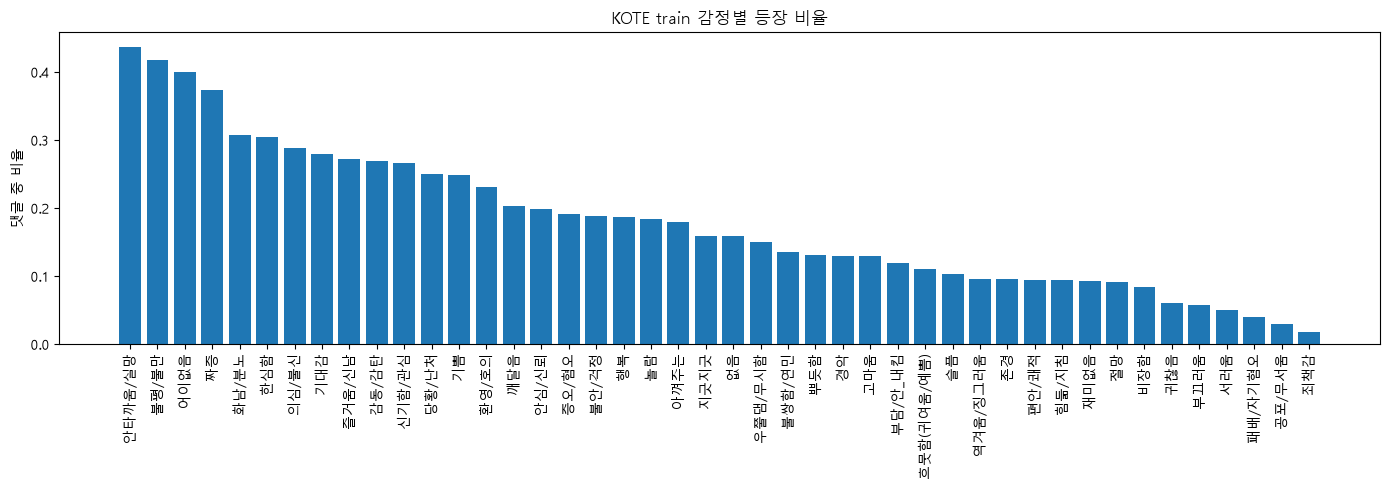

In [6]:
# 감정별 분포 확인

dist = pd.DataFrame({
    'label':       LABELS,
    'train_cnt':   y_train.sum(axis=0).astype(int),
    'train_ratio': y_train.mean(axis=0),   # 전체 댓글 중 해당 감정 비율
    'val_ratio':   y_val.mean(axis=0),
    'test_ratio':  y_test.mean(axis=0),
}).sort_values('train_cnt', ascending=False)
display(dist)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(dist['label'], dist['train_ratio'])
ax.set_ylabel('댓글 중 비율')
ax.set_title('KOTE train 감정별 등장 비율')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [7]:
# 불균형 및 라벨 확인

print('최다/최소 비율:', dist['train_cnt'].max() / dist['train_cnt'].min())
none_idx = LABELS.index('없음')

print('없음만 있는 댓글   :', ((y_train[:, none_idx] == 1) & (y_train.sum(axis=1) == 1)).sum())
print('없음 + 다른 감정   :', ((y_train[:, none_idx] == 1) & (y_train.sum(axis=1) > 1)).sum())

최다/최소 비율: 25.021489971346703
없음만 있는 댓글   : 83
없음 + 다른 감정   : 6261


In [8]:
# 텍스트 길이 계산 (글자 수, 공백 기준 단어 수)

for df in (train_df, val_df, test_df):
    df['char_len'] = df['text'].str.len()
    df['word_len'] = df['text'].str.split().str.len()

print(train_df[['char_len', 'word_len']].describe().round(1))

       char_len  word_len
count   40000.0   40000.0
mean       57.2      12.4
std        44.9      10.1
min        10.0       1.0
25%        28.0       6.0
50%        42.0       9.0
75%        71.0      16.0
max       404.0      98.0


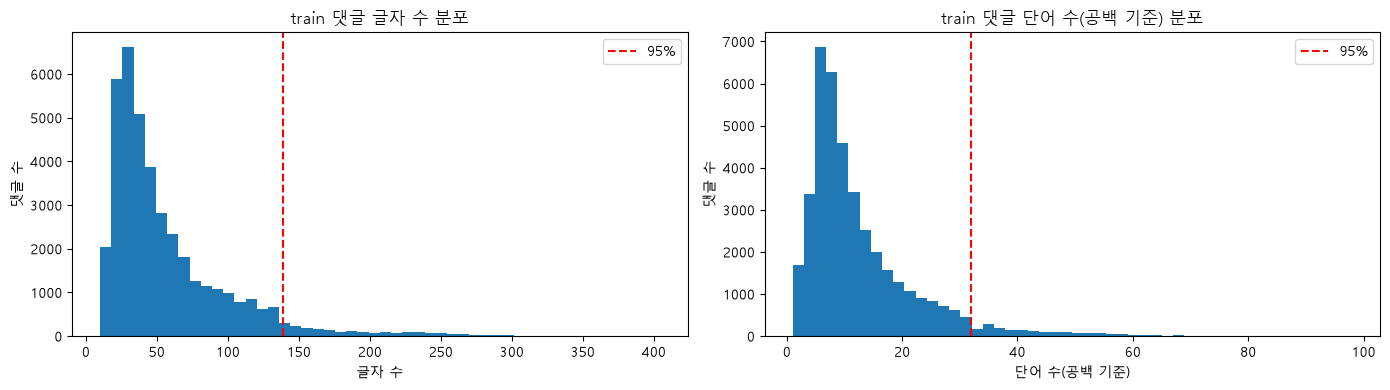

In [9]:
# 길이 분포 히스토그램

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, col, title in zip(axes, ['char_len', 'word_len'], ['글자 수', '단어 수(공백 기준)']):
    ax.hist(train_df[col], bins=50)
    ax.axvline(np.percentile(train_df[col], 95), color='red', linestyle='--', label='95%')
    ax.set_title(f'train 댓글 {title} 분포')
    ax.set_xlabel(title)
    ax.set_ylabel('댓글 수')
    ax.legend()
    
plt.tight_layout()
plt.show()

In [10]:
# 백분위수와 max_len 후보별 커버 비율

for q in [50, 90, 95, 99]:
    print(f'{q}% 지점 - 글자 수: {np.percentile(train_df["char_len"], q):.0f}, '
          f'단어 수: {np.percentile(train_df["word_len"], q):.0f}')

for max_len in [20, 30, 40, 50, 60]:
    ratio = (train_df['word_len'] <= max_len).mean()
    print(f'단어 수 {max_len} 이하 댓글 비율: {ratio:.2%}')

50% 지점 - 글자 수: 42, 단어 수: 9
90% 지점 - 글자 수: 115, 단어 수: 25
95% 지점 - 글자 수: 139, 단어 수: 32
99% 지점 - 글자 수: 237, 단어 수: 52
단어 수 20 이하 댓글 비율: 84.07%
단어 수 30 이하 댓글 비율: 94.36%
단어 수 40 이하 댓글 비율: 97.69%
단어 수 50 이하 댓글 비율: 98.87%
단어 수 60 이하 댓글 비율: 99.59%


In [11]:
# 길이에 따라 감정 개수 확인

train_df['n_labels'] = y_train.sum(axis=1)
len_bins = pd.cut(train_df['char_len'], bins=[0, 20, 50, 100, 200, 1000])
print(train_df.groupby(len_bins, observed=True)['n_labels'].agg(['count', 'mean']).round(2))

             count  mean
char_len                
(0, 20]       3375  7.22
(20, 50]     20541  7.77
(50, 100]    10600  8.19
(100, 200]    4696  8.34
(200, 1000]    788  8.35


In [12]:
# 형태소 분석

mecab = MeCab()
for df in (train_df, val_df, test_df):
    df['morphs'] = df['text'].apply(mecab.morphs)
    df['morph_len'] = df['morphs'].str.len()

# 공백, 형태소 기준
sample = train_df['text'].iloc[0]
print(sample)
print('공백  :', sample.split())
print('형태소:', mecab.morphs(sample))

내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.
공백  : ['내가', '톰행크스를', '좋아하긴', '했나보다...', '초기', '영화', '빼고는', '다', '봤네.']
형태소: ['내', '가', '톰행크스', '를', '좋아하', '긴', '했', '나', '보', '다', '.', '..', '초기', '영화', '빼', '고', '는', '다', '봤', '네', '.']


In [13]:
# 형태소 기준 길이 통계
# max_len 후보별 커버 비율

print(train_df['morph_len'].describe().round(1))
print('단어 1개당 평균 형태소 수:', (train_df['morph_len'] / train_df['word_len']).mean().round(2))

for q in [50, 90, 95, 99]:
    print(f'{q}% 지점 - 형태소 수: {np.percentile(train_df["morph_len"], q):.0f}')

for max_len in [32, 48, 64, 80, 100, 128]:
    ratio = (train_df['morph_len'] <= max_len).mean()
    print(f'형태소 {max_len}개 이하 댓글 비율: {ratio:.2%}')

count    40000.0
mean        29.2
std         23.1
min          1.0
25%         14.0
50%         22.0
75%         36.0
max        232.0
Name: morph_len, dtype: float64
단어 1개당 평균 형태소 수: 2.64
50% 지점 - 형태소 수: 22
90% 지점 - 형태소 수: 58
95% 지점 - 형태소 수: 72
99% 지점 - 형태소 수: 122
형태소 32개 이하 댓글 비율: 70.55%
형태소 48개 이하 댓글 비율: 84.72%
형태소 64개 이하 댓글 비율: 92.52%
형태소 80개 이하 댓글 비율: 96.26%
형태소 100개 이하 댓글 비율: 97.89%
형태소 128개 이하 댓글 비율: 99.31%


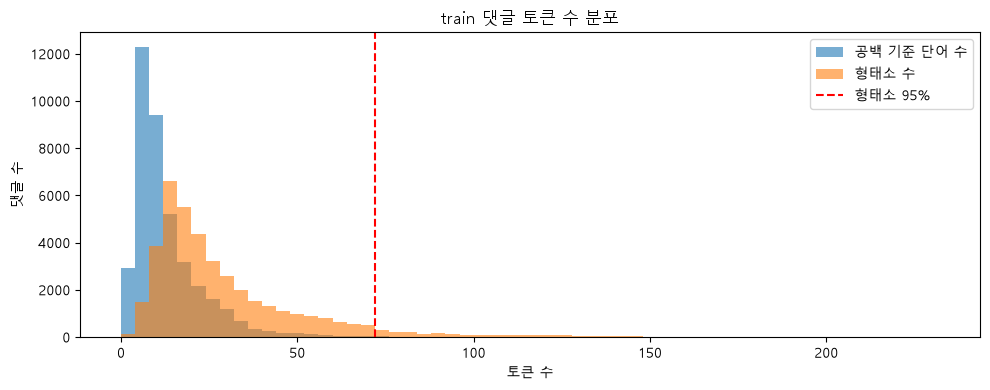

In [14]:
# 공백, 형태소 기준 분포 비교

bins = np.arange(0, train_df['morph_len'].max() + 4, 4)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(train_df['word_len'], bins=bins, alpha=0.6, label='공백 기준 단어 수')
ax.hist(train_df['morph_len'], bins=bins, alpha=0.6, label='형태소 수')
ax.axvline(np.percentile(train_df['morph_len'], 95), color='red', linestyle='--', label='형태소 95%')
ax.set_title('train 댓글 토큰 수 분포')
ax.set_xlabel('토큰 수')
ax.set_ylabel('댓글 수')
ax.legend()

plt.tight_layout()
plt.show()

In [15]:
# 형태소 등장 빈도 세기

counter = Counter()
for morphs in train_df['morphs']:
    counter.update(morphs)

total = sum(counter.values())
print('train 고유 형태소 수:', len(counter))
print('가장 많이 나온 형태소:', counter.most_common(10))

# min_freq 후보별 vocab 크기, train 토큰 커버 비율
for min_freq in [1, 2, 3, 5, 10]:
    kept = [w for w, f in counter.items() if f >= min_freq]
    coverage = sum(counter[w] for w in kept) / total
    print(f'min_freq={min_freq:>2} → vocab {len(kept):>6}개, train 토큰 커버 {coverage:.2%}')

train 고유 형태소 수: 44241
가장 많이 나온 형태소: [('.', 48090), ('이', 31915), ('는', 26728), ('하', 23677), ('고', 21761), ('가', 14854), ('에', 14667), ('도', 14464), ('은', 14263), ('다', 12419)]
min_freq= 1 → vocab  44241개, train 토큰 커버 100.00%
min_freq= 2 → vocab  24272개, train 토큰 커버 98.29%
min_freq= 3 → vocab  17724개, train 토큰 커버 97.17%
min_freq= 5 → vocab  11944개, train 토큰 커버 95.49%
min_freq=10 → vocab   7101개, train 토큰 커버 92.79%


In [16]:
# vocab 만들기
# 3번 미만 등장한 형태소는 <UNK> 처리

MIN_FREQ = 3

vocab = {'<PAD>': 0, '<UNK>': 1}

# 빈도 높은 순서로 번호 부여
for word, freq in counter.most_common(): 
    if freq >= MIN_FREQ:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)
print('vocab 크기:', VOCAB_SIZE)
print(list(vocab.items())[:12])

vocab 크기: 17726
[('<PAD>', 0), ('<UNK>', 1), ('.', 2), ('이', 3), ('는', 4), ('하', 5), ('고', 6), ('가', 7), ('에', 8), ('도', 9), ('은', 10), ('다', 11)]


In [17]:
# 정수 인코딩

def encode(morphs):
    return [vocab.get(token, vocab['<UNK>']) for token in morphs]

for df in (train_df, val_df, test_df):
    df['input_ids'] = df['morphs'].apply(encode)

print(train_df['morphs'].iloc[0])
print(train_df['input_ids'].iloc[0])

# split별 <UNK> 비율
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    ids = [i for row in df['input_ids'] for i in row]
    unk_ratio = sum(i == vocab['<UNK>'] for i in ids) / len(ids)
    print(f'{name:5} <UNK> 비율: {unk_ratio:.2%}')

['내', '가', '톰행크스', '를', '좋아하', '긴', '했', '나', '보', '다', '.', '..', '초기', '영화', '빼', '고', '는', '다', '봤', '네', '.']
[76, 7, 1, 30, 1601, 194, 40, 29, 27, 11, 2, 24, 2890, 61, 487, 6, 4, 11, 132, 49, 2]
train <UNK> 비율: 2.83%
val   <UNK> 비율: 3.68%
test  <UNK> 비율: 3.82%


In [18]:
# 패딩, 자르기

MAX_LEN = 80

def pad_ids(ids_list, max_len):
    X = np.zeros((len(ids_list), max_len), dtype=np.int64)   # 0 = <PAD>
    for i, ids in enumerate(ids_list):
        ids = ids[-max_len:]
        X[i, max_len - len(ids):] = ids
    return X

X_train = pad_ids(train_df['input_ids'], MAX_LEN)
X_val   = pad_ids(val_df['input_ids'], MAX_LEN)
X_test  = pad_ids(test_df['input_ids'], MAX_LEN)

print(X_train.shape, X_val.shape, X_test.shape)
print('잘린 train 댓글 비율:', (train_df['morph_len'] > MAX_LEN).mean().round(4))
print('train 전체 칸 중 <PAD> 비율:', (X_train == 0).mean().round(4))
print(X_train[0])

(40000, 80) (5000, 80) (5000, 80)
잘린 train 댓글 비율: 0.0374
train 전체 칸 중 <PAD> 비율: 0.6491
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0   76    7    1   30 1601  194   40   29   27   11    2
   24 2890   61  487    6    4   11  132   49    2]


In [19]:
# 데이터로더

class KoteDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [20]:
# 데이터로더

BATCH_SIZE = 64

train_loader = DataLoader(KoteDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(KoteDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(KoteDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

# shape 확인
xb, yb = next(iter(train_loader))
print('X batch:', xb.shape, xb.dtype)   # (batch_size, sequence_length)
print('y batch:', yb.shape, yb.dtype)   # (batch_size, 44)
print('배치 수 - train:', len(train_loader), 'val:', len(val_loader), 'test:', len(test_loader))

X batch: torch.Size([64, 80]) torch.int64
y batch: torch.Size([64, 44]) torch.float32
배치 수 - train: 625 val: 79 test: 79


In [21]:
# 모델

class KoteLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_size=128, num_layers=2,
                 num_labels=NUM_LABELS, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_labels)

    def forward(self, x):
        emb = self.embedding(x)
        out, (h_n, c_n) = self.lstm(emb)
        last_hidden = out[:, -1, :]
        logits = self.fc(self.dropout(last_hidden))
        return logits

In [22]:
# 모델 생성, 손실 함수, 옵티마이저, 하이퍼파라미터

torch.manual_seed(SEED)

model = KoteLSTM(VOCAB_SIZE).to(DEVICE)
print(model)
print('학습 파라미터 수:', sum(p.numel() for p in model.parameters() if p.requires_grad))

# 감정 각각을 독립적인 이진 분류로 봄
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

MAX_EPOCHS = 30
PATIENCE = 5
CLIP_NORM = 1.0
THRESHOLD = 0.3   # sigmoid 확률이 이 값 이상이면 그 감정이 있다고 예측

KoteLSTM(
  (embedding): Embedding(17726, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=44, bias=True)
)
학습 파라미터 수: 2538796


In [23]:
# 평가 함수
# loss, sigmoid, 정답

def predict_proba(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_count = 0
    probs = []
    trues = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            batch_size = xb.size(0)
            total_loss += loss.item() * batch_size
            total_count += batch_size

            probs.append(torch.sigmoid(logits).cpu().numpy())
            trues.append(yb.cpu().numpy())

    return total_loss / total_count, np.vstack(probs), np.vstack(trues)

In [24]:
# 학습 

best_val_f1 = 0.0
best_state = None
wait = 0

train_history = []
val_history = []
val_f1_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_count = 0
    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_NORM)
        optimizer.step()
        batch_size = xb.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size
    train_loss = train_loss_sum / train_count

    val_loss, val_prob, val_true = predict_proba(model, val_loader, criterion, DEVICE)
    val_pred = (val_prob >= THRESHOLD).astype(int)
    val_f1 = f1_score(val_true, val_pred, average='macro', zero_division=0)

    train_history.append(train_loss)
    val_history.append(val_loss)
    val_f1_history.append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.4f} | "
        f"Valid {val_loss:.4f} | "
        f"Valid macro F1 {val_f1:.4f}"
    )

    if wait >= PATIENCE:
        print("Early Stopping")
        break

if best_state is not None:
    model.load_state_dict(best_state)
print('best val macro F1:', round(best_val_f1, 4))

Epoch 01 | Train 0.4132 | Valid 0.3763 | Valid macro F1 0.2728
Epoch 02 | Train 0.3668 | Valid 0.3636 | Valid macro F1 0.3206
Epoch 03 | Train 0.3498 | Valid 0.3522 | Valid macro F1 0.3488
Epoch 04 | Train 0.3364 | Valid 0.3471 | Valid macro F1 0.3893
Epoch 05 | Train 0.3242 | Valid 0.3441 | Valid macro F1 0.4059
Epoch 06 | Train 0.3141 | Valid 0.3433 | Valid macro F1 0.4198
Epoch 07 | Train 0.3052 | Valid 0.3435 | Valid macro F1 0.4260
Epoch 08 | Train 0.2976 | Valid 0.3471 | Valid macro F1 0.4318
Epoch 09 | Train 0.2910 | Valid 0.3471 | Valid macro F1 0.4326
Epoch 10 | Train 0.2847 | Valid 0.3494 | Valid macro F1 0.4390
Epoch 11 | Train 0.2790 | Valid 0.3551 | Valid macro F1 0.4372
Epoch 12 | Train 0.2741 | Valid 0.3572 | Valid macro F1 0.4432
Epoch 13 | Train 0.2692 | Valid 0.3610 | Valid macro F1 0.4394
Epoch 14 | Train 0.2647 | Valid 0.3638 | Valid macro F1 0.4388
Epoch 15 | Train 0.2598 | Valid 0.3678 | Valid macro F1 0.4434
Epoch 16 | Train 0.2561 | Valid 0.3694 | Valid macro F1

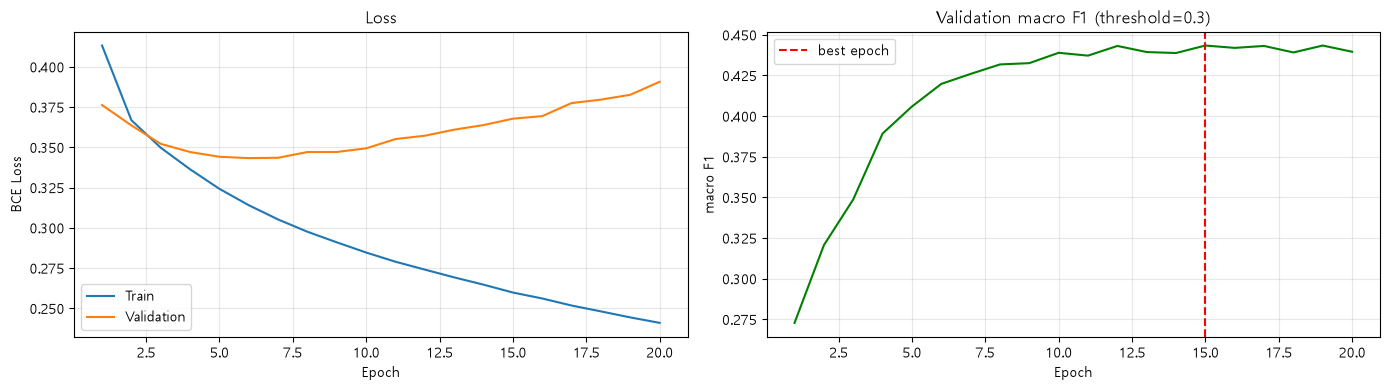

In [25]:
# 학습 곡선
# loss, val macro F1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(range(1, len(train_history) + 1), train_history, label='Train')
axes[0].plot(range(1, len(val_history) + 1), val_history, label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, len(val_f1_history) + 1), val_f1_history, color='green')
axes[1].axvline(int(np.argmax(val_f1_history)) + 1, color='red', linestyle='--', label='best epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('macro F1')
axes[1].set_title(f'Validation macro F1 (threshold={THRESHOLD})')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# test 평가 (threshold 0.3, KOTE 제작자와 같은 조건)

test_loss, test_prob, test_true = predict_proba(model, test_loader, criterion, DEVICE)
test_pred = (test_prob >= THRESHOLD).astype(int)

test_micro = f1_score(test_true, test_pred, average='micro', zero_division=0)
test_macro = f1_score(test_true, test_pred, average='macro', zero_division=0)

print(f'test loss    : {test_loss:.4f}')
print(f'test micro F1: {test_micro:.4f}')
print(f'test macro F1: {test_macro:.4f}   (KcELECTRA 0.56)')
print('댓글당 평균 예측 감정 수:', test_pred.sum(axis=1).mean().round(2),
      '/ 정답 평균:', test_true.sum(axis=1).mean().round(2))

test loss    : 0.3716
test micro F1: 0.5514
test macro F1: 0.4362   (KcELECTRA 0.56)
댓글당 평균 예측 감정 수: 9.74 / 정답 평균: 7.93


In [27]:
# threshold 실험 1: 전체 감정에 같은 threshold 적용, val로 고름

val_loss, val_prob, val_true = predict_proba(model, val_loader, criterion, DEVICE)

thresholds = np.arange(0.10, 0.65, 0.05).round(2)
rows = []
for t in thresholds:
    pred = (val_prob >= t).astype(int)
    rows.append({
        'threshold':    t,
        'micro_f1':     f1_score(val_true, pred, average='micro', zero_division=0),
        'macro_f1':     f1_score(val_true, pred, average='macro', zero_division=0),
        'avg_pred_cnt': pred.sum(axis=1).mean(),   # 댓글당 예측 감정 수
    })
th_df = pd.DataFrame(rows)
display(th_df.round(4))

BEST_TH = th_df.loc[th_df['macro_f1'].idxmax(), 'threshold']
print('val macro F1 기준 best threshold:', BEST_TH)

,threshold,micro_f1,macro_f1,avg_pred_cnt
0,0.10,0.5010,0.4367,17.8514
1,0.15,0.5266,0.4474,14.9344
2,0.20,0.5418,0.4519,12.8356
3,0.25,0.5519,0.4497,11.1822
4,0.30,0.5559,0.4434,9.8354
5,0.35,0.5545,0.4316,8.6912
6,0.40,0.5476,0.4167,7.6864
7,0.45,0.5387,0.4014,6.7890
8,0.50,0.5237,0.3787,5.9634
9,0.55,0.5047,0.3538,5.2108


val macro F1 기준 best threshold: 0.2


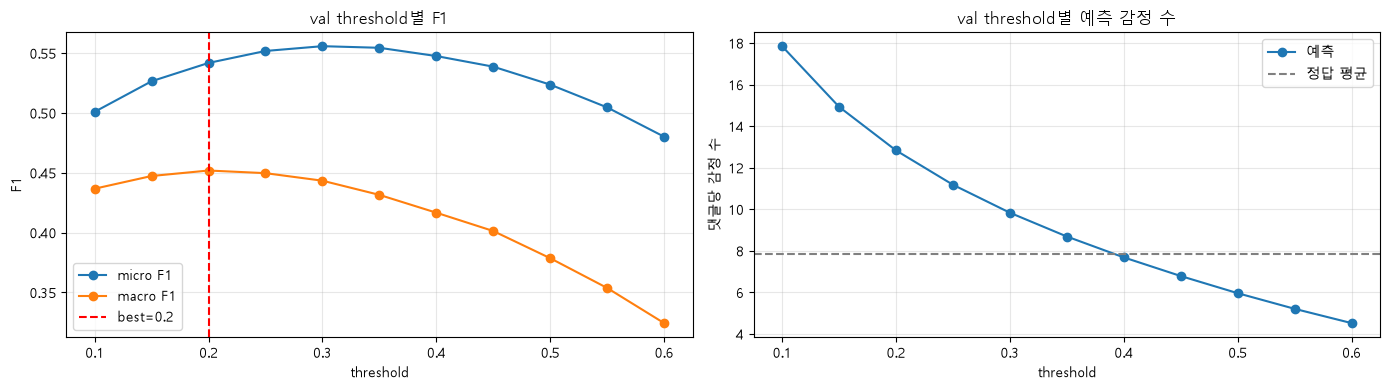

In [28]:
# threshold에 따른 F1, 예측 감정 수 변화

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(th_df['threshold'], th_df['micro_f1'], marker='o', label='micro F1')
axes[0].plot(th_df['threshold'], th_df['macro_f1'], marker='o', label='macro F1')
axes[0].axvline(BEST_TH, color='red', linestyle='--', label=f'best={BEST_TH}')
axes[0].set_xlabel('threshold')
axes[0].set_ylabel('F1')
axes[0].set_title('val threshold별 F1')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(th_df['threshold'], th_df['avg_pred_cnt'], marker='o', label='예측')
axes[1].axhline(val_true.sum(axis=1).mean(), color='gray', linestyle='--', label='정답 평균')
axes[1].set_xlabel('threshold')
axes[1].set_ylabel('댓글당 감정 수')
axes[1].set_title('val threshold별 예측 감정 수')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
# threshold 실험 2: 감정마다 threshold를 따로 고름 (val 기준)

per_label_th = np.zeros(NUM_LABELS)
for j in range(NUM_LABELS):
    scores = [f1_score(val_true[:, j], (val_prob[:, j] >= t).astype(int), zero_division=0)
              for t in thresholds]
    per_label_th[j] = thresholds[int(np.argmax(scores))]

print(pd.Series(per_label_th, index=LABELS).sort_values().to_string())

귀찮음            0.10
죄책감            0.10
공포/무서움         0.10
부끄러움           0.10
패배/자기혐오        0.15
절망             0.15
부담/안_내킴        0.15
지긋지긋           0.20
없음             0.20
놀람             0.20
서러움            0.20
우쭐댐/무시함        0.20
뿌듯함            0.25
아껴주는           0.25
화남/분노          0.25
감동/감탄          0.25
짜증             0.25
깨달음            0.25
역겨움/징그러움       0.25
경악             0.25
흐뭇함(귀여움/예쁨)    0.25
편안/쾌적          0.25
기대감            0.25
힘듦/지침          0.25
당황/난처          0.25
행복             0.25
어이없음           0.30
환영/호의          0.30
불평/불만          0.30
슬픔             0.30
안타까움/실망        0.30
비장함            0.30
불쌍함/연민         0.30
불안/걱정          0.30
의심/불신          0.30
재미없음           0.30
존경             0.35
고마움            0.35
한심함            0.35
신기함/관심         0.35
기쁨             0.35
즐거움/신남         0.35
안심/신뢰          0.35
증오/혐오          0.40


In [30]:
# test에서 세 가지 threshold 방식 비교

test_preds = {
    '0.3 (KOTE 제작자)':      (test_prob >= 0.3).astype(int),
    f'{BEST_TH} (val best)':  (test_prob >= BEST_TH).astype(int),
    '감정별 threshold':        (test_prob >= per_label_th).astype(int),
}

compare = pd.DataFrame([{
    'threshold':    name,
    'micro_f1':     f1_score(test_true, pred, average='micro', zero_division=0),
    'macro_f1':     f1_score(test_true, pred, average='macro', zero_division=0),
    'avg_pred_cnt': pred.sum(axis=1).mean(),
} for name, pred in test_preds.items()])
display(compare.round(4))

,threshold,micro_f1,macro_f1,avg_pred_cnt
0,0.3 (KOTE 제작자),0.5514,0.4362,9.7426
1,0.2 (val best),0.5414,0.4505,12.7614
2,감정별 threshold,0.5329,0.4560,11.5142


In [31]:
# 감정별 성능 (test, val best threshold 적용)
# classification_report를 DataFrame으로 바꿔서 train 빈도 비교
final_pred = (test_prob >= BEST_TH).astype(int)

report = classification_report(test_true, final_pred, target_names=LABELS,
                               output_dict=True, zero_division=0)

label_df = pd.DataFrame(report).T.loc[LABELS]   # micro/macro avg 행은 빼고 감정 44개만
label_df['train_ratio'] = y_train.mean(axis=0)   # train에서 이 감정이 붙은 댓글 비율
label_df['support'] = label_df['support'].astype(int)
label_df = label_df.sort_values('f1-score', ascending=False)

display(label_df.round(3))

,precision,recall,f1-score,support,train_ratio
불평/불만,0.646,0.885,0.747,2113,0.417
짜증,0.627,0.840,0.718,1909,0.373
어이없음,0.585,0.879,0.702,2055,0.400
안타까움/실망,0.573,0.905,0.702,2185,0.437
화남/분노,0.605,0.795,0.687,1538,0.307
즐거움/신남,0.583,0.793,0.672,1321,0.272
기쁨,0.564,0.801,0.662,1205,0.249
감동/감탄,0.547,0.791,0.646,1323,0.269
한심함,0.493,0.827,0.617,1519,0.305
의심/불신,0.476,0.845,0.609,1539,0.289


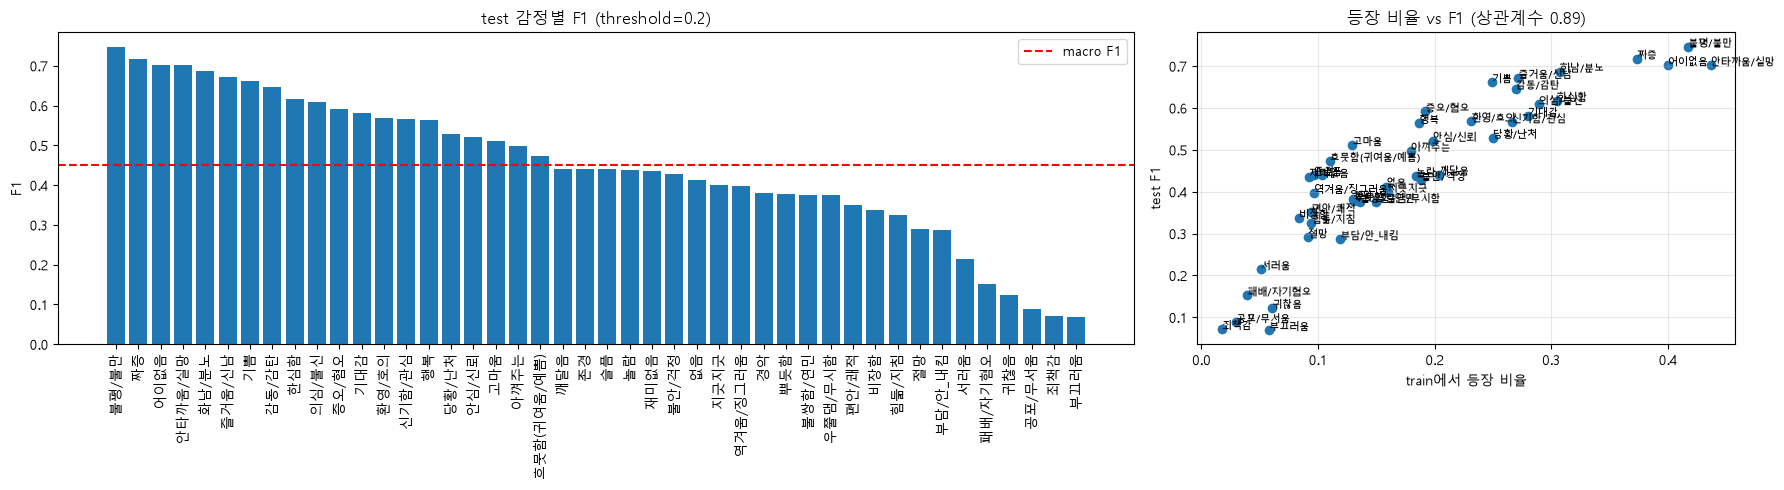

In [32]:
# 감정별 F1 막대그래프 + train 빈도와 F1의 관계

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

axes[0].bar(label_df.index, label_df['f1-score'])
axes[0].axhline(label_df['f1-score'].mean(), color='red', linestyle='--', label='macro F1')
axes[0].set_ylabel('F1')
axes[0].set_title(f'test 감정별 F1 (threshold={BEST_TH})')
axes[0].tick_params(axis='x', rotation=90)
axes[0].legend()

axes[1].scatter(label_df['train_ratio'], label_df['f1-score'])
for name, row in label_df.iterrows():
    axes[1].annotate(name, (row['train_ratio'], row['f1-score']), fontsize=7)
corr = np.corrcoef(label_df['train_ratio'], label_df['f1-score'])[0, 1]
axes[1].set_xlabel('train에서 등장 비율')
axes[1].set_ylabel('test F1')
axes[1].set_title(f'등장 비율 vs F1 (상관계수 {corr:.2f})')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# 분류 잘되는, 안되는 감정
# precision/recall

cols = ['precision', 'recall', 'f1-score', 'support', 'train_ratio']
print('F1 상위 5개')
display(label_df[cols].head(5).round(3))
print('F1 하위 5개')
display(label_df[cols].tail(5).round(3))


# 희귀 감정과 나머지 평균 F1 비교
rare = label_df['train_ratio'] < 0.10
print(f'희귀 감정 {rare.sum()}개 평균 F1: {label_df.loc[rare, "f1-score"].mean():.3f}')
print(f'나머지 {(~rare).sum()}개 평균 F1: {label_df.loc[~rare, "f1-score"].mean():.3f}')

F1 상위 5개


,precision,recall,f1-score,support,train_ratio
불평/불만,0.646,0.885,0.747,2113,0.417
짜증,0.627,0.840,0.718,1909,0.373
어이없음,0.585,0.879,0.702,2055,0.400
안타까움/실망,0.573,0.905,0.702,2185,0.437
화남/분노,0.605,0.795,0.687,1538,0.307


F1 하위 5개


,precision,recall,f1-score,support,train_ratio
패배/자기혐오,0.161,0.144,0.152,208,0.040
귀찮음,0.134,0.114,0.123,290,0.061
공포/무서움,0.161,0.061,0.088,164,0.030
죄책감,0.148,0.048,0.072,84,0.017
부끄러움,0.104,0.052,0.070,306,0.058


희귀 감정 13개 평균 F1: 0.254
나머지 31개 평균 F1: 0.533


In [34]:
# 틀린 예측 분석 준비: 댓글 하나씩 정답/예측 비교
# test_loader는 shuffle=False라서 test_prob의 i번째 행 = test_df의 i번째 댓글

def sample_f1(true, pred):
    # 댓글별 F1: 2 * 겹친 감정 수 / (정답 감정 수 + 예측 감정 수)
    overlap = (true * pred).sum(axis=1)
    denom = true.sum(axis=1) + pred.sum(axis=1)
    return np.where(denom > 0, 2 * overlap / np.maximum(denom, 1), 1.0)

result_df = test_df[['text', 'morph_len']].copy().reset_index(drop=True)
result_df['f1'] = sample_f1(test_true, final_pred)
result_df['n_true'] = test_true.sum(axis=1).astype(int)
result_df['n_pred'] = final_pred.sum(axis=1).astype(int)

def show_example(i):
    true_set = set(np.where(test_true[i] == 1)[0])
    pred_set = set(np.where(final_pred[i] == 1)[0])
    print(f"[{i}] {result_df.loc[i, 'text']}")
    print(f"  댓글 F1 {result_df.loc[i, 'f1']:.2f}")
    print('  맞춤  :', [LABELS[j] for j in sorted(true_set & pred_set)])
    print('  놓침  :', [LABELS[j] for j in sorted(true_set - pred_set)])
    print('  오답  :', [f'{LABELS[j]}({test_prob[i, j]:.2f})' for j in sorted(pred_set - true_set)])
    print()

print('test 댓글 F1 평균:', result_df['f1'].mean().round(3))
show_example(0)

test 댓글 F1 평균: 0.536
[0] 개인적으로 원빈이 더 늙기전에 데이빗(톰크루즈) 역활로 한국판 리메이크 개봉 했으면 함...
  댓글 F1 0.22
  맞춤  : ['기대감']
  놓침  : []
  오답  : ['환영/호의(0.34)', '우쭐댐/무시함(0.23)', '비장함(0.63)', '신기함/관심(0.26)', '없음(0.87)', '깨달음(0.32)', '안심/신뢰(0.47)']



In [35]:
# 가장 많이 틀린 댓글 10개 (댓글 F1이 낮은 순)

worst_idx = result_df.sort_values('f1').index[:10]
for i in worst_idx:
    show_example(i)

[14] 박정희와 존경이란 단어는 어울릴수가 없다
  댓글 F1 0.00
  맞춤  : []
  놓침  : ['불평/불만', '비장함', '짜증', '어이없음', '증오/혐오', '부담/안_내킴']
  오답  : ['환영/호의(0.62)', '감동/감탄(0.97)', '존경(0.77)', '기대감(0.73)', '신기함/관심(0.80)', '깨달음(0.31)', '놀람(0.56)', '안심/신뢰(0.41)']

[1796] 리뷰에서 적힌데로 길고 큼직주방에서 한눈에 보일사이즈대는 조금 짧아도..다른 제품들 짧게만 나오길래 아기보온병도 씻고싶어 샀더니 아주 넉넉한 사이즈... 실리콘제품들도 있었지만 요건 양쪽붙어있어 한눈에 쏙~~배송중 안뜨더니 급뜨면서 헐~ 총알배송보여줌 ... 날아왔구나
  댓글 F1 0.00
  맞춤  : []
  놓침  : ['환영/호의', '감동/감탄', '고마움', '기대감', '뿌듯함', '신기함/관심', '즐거움/신남', '흐뭇함(귀여움/예쁨)', '놀람', '행복', '기쁨', '안심/신뢰']
  오답  : ['불평/불만(0.99)', '화남/분노(0.69)', '안타까움/실망(0.95)', '의심/불신(0.52)', '짜증(0.94)', '어이없음(0.84)', '당황/난처(0.93)', '부담/안_내킴(0.23)', '불안/걱정(0.22)']

[4272] 개봉 당일에 봤었다. 기억에 남는건 피랑 일락이, 고기만두
  댓글 F1 0.00
  맞춤  : []
  놓침  : ['불평/불만', '안타까움/실망', '어이없음', '부담/안_내킴', '재미없음']
  오답  : ['환영/호의(0.67)', '감동/감탄(0.84)', '기대감(0.58)', '뿌듯함(0.26)', '신기함/관심(0.83)', '아껴주는(0.71)', '즐거움/신남(0.77)', '흐뭇함(귀여움/예쁨)(0.89)', '놀람(0.27)', '행복(0.64)', '기쁨(0.72)']

[1957] 비오는날이면 수리비도 줘야되는거아님? 치료비 수리비 합의금 사과

In [36]:
# 길이, <UNK> 개수에 따라 댓글 F1이 달라지는지

result_df['n_unk'] = test_df['input_ids'].apply(lambda ids: ids.count(vocab['<UNK>'])).values
result_df['truncated'] = result_df['morph_len'] > MAX_LEN

len_bins = pd.cut(result_df['morph_len'], bins=[0, 10, 20, 40, 80, 300])
print('형태소 길이별')
print(result_df.groupby(len_bins, observed=True)['f1'].agg(['count', 'mean']).round(3))

print('\nMAX_LEN으로 잘렸는지')
print(result_df.groupby('truncated')['f1'].agg(['count', 'mean']).round(3))

unk_bins = pd.cut(result_df['n_unk'], bins=[-1, 0, 1, 3, 100], labels=['0개', '1개', '2~3개', '4개 이상'])
print('\n<UNK> 개수별')
print(result_df.groupby(unk_bins, observed=True)['f1'].agg(['count', 'mean']).round(3))

형태소 길이별
           count   mean
morph_len              
(0, 10]      525  0.516
(10, 20]    1835  0.510
(20, 40]    1604  0.548
(40, 80]     830  0.558
(80, 300]    206  0.635

MAX_LEN으로 잘렸는지
           count   mean
truncated              
False       4794  0.532
True         206  0.635

<UNK> 개수별
       count   mean
n_unk              
0개      2143  0.544
1개      1432  0.537
2~3개    1112  0.521
4개 이상    313  0.529


In [37]:
# 감정 극성(긍정/부정)이 뒤집힌 사례 찾기
# 44개 감정을 긍정/부정으로 묶음 (직접 나눈 기준, 비장함·깨달음·경악·놀람·없음은 중립으로 제외)
POS = ['환영/호의', '감동/감탄', '고마움', '존경', '기대감', '뿌듯함', '편안/쾌적', '신기함/관심',
       '아껴주는', '즐거움/신남', '흐뭇함(귀여움/예쁨)', '행복', '기쁨', '안심/신뢰']
NEG = ['불평/불만', '지긋지긋', '슬픔', '화남/분노', '우쭐댐/무시함', '안타까움/실망', '의심/불신',
       '부끄러움', '공포/무서움', '절망', '한심함', '역겨움/징그러움', '짜증', '어이없음',
       '패배/자기혐오', '귀찮음', '힘듦/지침', '죄책감', '증오/혐오', '당황/난처', '부담/안_내킴',
       '서러움', '재미없음', '불쌍함/연민', '불안/걱정']
pos_idx = [LABELS.index(l) for l in POS]
neg_idx = [LABELS.index(l) for l in NEG]

def polarity(y):
    # 긍정 감정 수 - 부정 감정 수의 부호: 1(긍정), -1(부정), 0(동률)
    return np.sign(y[:, pos_idx].sum(axis=1) - y[:, neg_idx].sum(axis=1))

result_df['true_pol'] = polarity(test_true)
result_df['pred_pol'] = polarity(final_pred)
result_df['flipped'] = (result_df['true_pol'] * result_df['pred_pol']) == -1   # 부호가 반대

print('극성이 뒤집힌 댓글:', result_df['flipped'].sum(), '/', len(result_df),
      f"({result_df['flipped'].mean():.2%})")
print('  정답 부정 → 예측 긍정:', (result_df['flipped'] & (result_df['true_pol'] == -1)).sum())
print('  정답 긍정 → 예측 부정:', (result_df['flipped'] & (result_df['true_pol'] == 1)).sum())
print('뒤집힌 댓글 평균 F1:', result_df.loc[result_df['flipped'], 'f1'].mean().round(3),
      '/ 나머지:', result_df.loc[~result_df['flipped'], 'f1'].mean().round(3))

극성이 뒤집힌 댓글: 749 / 5000 (14.98%)
  정답 부정 → 예측 긍정: 358
  정답 긍정 → 예측 부정: 391
뒤집힌 댓글 평균 F1: 0.281 / 나머지: 0.581


In [38]:
# 부정어(안, 않, 못)가 있는 댓글은 더 많이 틀리는지
# MeCab 형태소 기준: '안 좋다' → ['안', '좋', '다'], '좋지 않다' → ['좋', '지', '않', '다']

NEGATION = {'안', '않', '못'}
result_df['has_negation'] = test_df['morphs'].apply(lambda ms: any(m in NEGATION for m in ms)).values

print(result_df.groupby('has_negation')[['f1', 'flipped']].agg(['count', 'mean']).round(3))

# 부정어가 있으면서 극성이 뒤집힌 사례
neg_flip_idx = result_df[result_df['has_negation'] & result_df['flipped']].index[:8]
for i in neg_flip_idx:
    show_example(i)

                f1        flipped       
             count   mean   count   mean
has_negation                            
False         3947  0.530    3947  0.156
True          1053  0.558    1053  0.125
[38] 치팅데이는 보디빌더가 대회전 몸 만들때 탄수화물을 늘리는게 치팅이고..초고도비만 돼지 다이어터는 치팅이 필요없습니다. 보상데이가 맞죠. 그냥 이날은 먹을래 하고 자기만족하는 날인데, 그것마저 적당히 안먹고 치킨,피자 떡볶이 먹으면 당연히 도로쪄요
  댓글 F1 0.10
  맞춤  : ['우쭐댐/무시함']
  놓침  : ['안타까움/실망', '한심함', '어이없음', '당황/난처', '불안/걱정']
  오답  : ['환영/호의(0.58)', '감동/감탄(0.87)', '존경(0.27)', '기대감(0.77)', '뿌듯함(0.42)', '신기함/관심(0.86)', '아껴주는(0.31)', '즐거움/신남(0.85)', '깨달음(0.61)', '흐뭇함(귀여움/예쁨)(0.30)', '놀람(0.55)', '행복(0.42)', '기쁨(0.65)', '안심/신뢰(0.46)']

[103] 안 안 안 안 안!!!!!앙앙앙!!!
  댓글 F1 0.25
  맞춤  : ['기대감', '짜증', '없음']
  놓침  : ['환영/호의', '존경', '비장함', '즐거움/신남', '불쌍함/연민', '안심/신뢰']
  오답  : ['불평/불만(0.56)', '감동/감탄(0.31)', '화남/분노(0.56)', '안타까움/실망(0.30)', '의심/불신(0.30)', '신기함/관심(0.36)', '한심함(0.23)', '어이없음(0.59)', '증오/혐오(0.25)', '당황/난처(0.49)', '경악(0.49)', '놀람(0.71)']

[132] 사랑한 시간만큼은 행복 하고 좋았으니  후회하지 않음 다만 보고싶은 마

In [39]:
# 비교 실험용 평가 함수
# 모든 모델을 같은 방식으로 평가: val에서 macro F1이 가장 높은 threshold를 골라 test에 적용

def evaluate_with_val_threshold(val_prob, val_true, test_prob, test_true, candidates):
    val_scores = [f1_score(val_true, (val_prob >= t).astype(int), average='macro', zero_division=0)
                  for t in candidates]
    best_t = candidates[int(np.argmax(val_scores))]
    pred = (test_prob >= best_t).astype(int)
    return {
        'threshold':    round(float(best_t), 2),
        'val_macro':    max(val_scores),
        'test_micro':   f1_score(test_true, pred, average='micro', zero_division=0),
        'test_macro':   f1_score(test_true, pred, average='macro', zero_division=0),
        'avg_pred_cnt': pred.sum(axis=1).mean(),
    }

In [ ]:
# baseline 1: 빈도 기반

train_ratio = y_train.mean(axis=0)
freq_val_prob  = np.tile(train_ratio, (len(y_val), 1))
freq_test_prob = np.tile(train_ratio, (len(y_test), 1))

freq_result = evaluate_with_val_threshold(freq_val_prob, y_val, freq_test_prob, y_test,
                                          candidates=np.arange(0.01, 0.50, 0.01).round(2))
print(freq_result)
print('예측하는 감정:', [LABELS[j] for j in np.where(train_ratio >= freq_result['threshold'])[0]])

{'threshold': 0.01, 'val_macro': 0.2900842465029732, 'test_micro': 0.3054176567777517, 'test_macro': 0.2921409935745952, 'avg_pred_cnt': np.float64(44.0)}
예측하는 감정: ['불평/불만', '환영/호의', '감동/감탄', '지긋지긋', '고마움', '슬픔', '화남/분노', '존경', '기대감', '우쭐댐/무시함', '안타까움/실망', '비장함', '의심/불신', '뿌듯함', '편안/쾌적', '신기함/관심', '아껴주는', '부끄러움', '공포/무서움', '절망', '한심함', '역겨움/징그러움', '짜증', '어이없음', '없음', '패배/자기혐오', '귀찮음', '힘듦/지침', '즐거움/신남', '깨달음', '죄책감', '증오/혐오', '흐뭇함(귀여움/예쁨)', '당황/난처', '경악', '부담/안_내킴', '서러움', '재미없음', '불쌍함/연민', '놀람', '행복', '불안/걱정', '기쁨', '안심/신뢰']


In [ ]:
# 비교 실험용 학습 함수

def run_experiment(model):
    model = model.to(DEVICE)
    exp_optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    best_f1, best_state, wait, epochs = 0.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            exp_optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_NORM)
            exp_optimizer.step()

        _, v_prob, v_true = predict_proba(model, val_loader, criterion, DEVICE)
        v_f1 = f1_score(v_true, (v_prob >= THRESHOLD).astype(int), average='macro', zero_division=0)
        epochs = epoch
        if v_f1 > best_f1:
            best_f1, best_state, wait = v_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    model.load_state_dict(best_state)
    _, v_prob, v_true = predict_proba(model, val_loader, criterion, DEVICE)
    _, t_prob, t_true = predict_proba(model, test_loader, criterion, DEVICE)
    result = evaluate_with_val_threshold(v_prob, v_true, t_prob, t_true, candidates=thresholds)
    result['epochs'] = epochs
    result['params'] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return result

In [ ]:
# baseline 2: 임베딩 평균

class MeanEmbedding(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, num_labels=NUM_LABELS, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(embedding_dim, num_labels)

    def forward(self, x):
        emb = self.embedding(x)                                  # (batch, 80, emb)
        mask = (x != 0).unsqueeze(-1).float()                    # <PAD> 위치는 0 → 평균에서 제외
        mean = (emb * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.fc(self.dropout(mean))

torch.manual_seed(SEED)
mean_result = run_experiment(MeanEmbedding(VOCAB_SIZE))
print(mean_result)

{'threshold': 0.2, 'val_macro': 0.45631807044956346, 'test_micro': 0.5527290495968727, 'test_macro': 0.4580472834510323, 'avg_pred_cnt': np.float64(12.5348), 'epochs': 30, 'params': 2274604}


In [ ]:
# baseline과 LSTM 비교

lstm_result = evaluate_with_val_threshold(val_prob, val_true, test_prob, test_true, candidates=thresholds)
lstm_result['epochs'] = len(train_history)
lstm_result['params'] = sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline_df = pd.DataFrame([
    {'model': '빈도 기반 (내용 안 봄)',      **freq_result},
    {'model': '임베딩 평균 (순서 안 봄)',    **mean_result},
    {'model': 'LSTM',                      **lstm_result},
    {'model': 'KcELECTRA (KOTE 논문)',     'test_macro': 0.56},
]).set_index('model')
display(baseline_df.round(4))

,threshold,val_macro,test_micro,test_macro,avg_pred_cnt,epochs,params
model,,,,,,,
빈도 기반 (내용 안 봄),0.01,0.2901,0.3054,0.2921,44.0000,NaN,NaN
임베딩 평균 (순서 안 봄),0.20,0.4563,0.5527,0.4580,12.5348,30.0,2274604.0
LSTM,0.20,0.4519,0.5414,0.4505,12.7614,20.0,2538796.0
KcELECTRA (KOTE 논문),NaN,NaN,NaN,0.5600,NaN,NaN,NaN


In [ ]:
# 하이퍼파라미터 비교 실험
# 기본 설정(embedding 128, hidden 128, layers 2, dropout 0.3)에서 한 번에 하나만 바꿔 비교

BASE = {'embedding_dim': 128, 'hidden_size': 128, 'num_layers': 2, 'dropout': 0.3}
changes = [
    {'hidden_size': 64},  {'hidden_size': 256},
    {'num_layers': 1},    {'num_layers': 3},
    {'embedding_dim': 64}, {'embedding_dim': 256},
    {'dropout': 0.1},     {'dropout': 0.5},
]

hp_rows = [{**BASE, 'changed': '기본', **lstm_result}]

for change in changes:
    config = {**BASE, **change}
    start = time.time()
    torch.manual_seed(SEED)   # 모든 실험이 같은 조건에서 시작하도록
    result = run_experiment(KoteLSTM(VOCAB_SIZE, **config))
    name = ', '.join(f'{k}={v}' for k, v in change.items())
    print(f"{name:20} | val macro {result['val_macro']:.4f} | test macro {result['test_macro']:.4f} "
          f"| {result['epochs']} epochs | {time.time() - start:.0f}초")
    hp_rows.append({**config, 'changed': name, **result})

hp_df = pd.DataFrame(hp_rows).set_index('changed')
display(hp_df.round(4))

hidden_size=64       | val macro 0.4361 | test macro 0.4440 | 25 epochs | 78초
hidden_size=256      | val macro 0.4522 | test macro 0.4500 | 20 epochs | 222초
num_layers=1         | val macro 0.4486 | test macro 0.4527 | 17 epochs | 51초
num_layers=3         | val macro 0.4426 | test macro 0.4418 | 25 epochs | 136초
embedding_dim=64     | val macro 0.4445 | test macro 0.4506 | 25 epochs | 94초
embedding_dim=256    | val macro 0.4536 | test macro 0.4534 | 15 epochs | 73초
dropout=0.1          | val macro 0.4510 | test macro 0.4546 | 15 epochs | 62초
dropout=0.5          | val macro 0.4465 | test macro 0.4483 | 23 epochs | 93초


,embedding_dim,hidden_size,num_layers,dropout,threshold,val_macro,test_micro,test_macro,avg_pred_cnt,epochs,params
changed,,,,,,,,,,,
기본,128,128,2,0.3,0.20,0.4519,0.5414,0.4505,12.7614,20,2538796
hidden_size=64,128,64,2,0.3,0.20,0.4361,0.5377,0.4440,13.2824,25,2354732
hidden_size=256,128,256,2,0.3,0.25,0.4522,0.5432,0.4500,11.0864,20,3201836
num_layers=1,128,128,1,0.3,0.20,0.4486,0.5439,0.4527,13.1020,17,2406700
num_layers=3,128,128,3,0.3,0.20,0.4426,0.5307,0.4418,13.0934,25,2670892
embedding_dim=64,64,128,2,0.3,0.20,0.4445,0.5389,0.4506,12.9216,25,1371564
embedding_dim=256,256,128,2,0.3,0.20,0.4536,0.5406,0.4534,13.3606,15,4873260
dropout=0.1,128,128,2,0.1,0.20,0.4510,0.5475,0.4546,12.9322,15,2538796
dropout=0.5,128,128,2,0.5,0.20,0.4465,0.5405,0.4483,12.7872,23,2538796


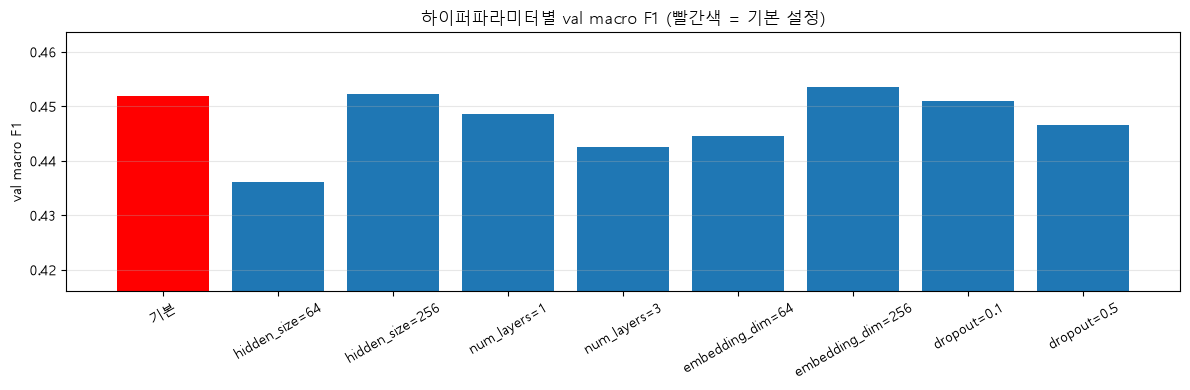

In [ ]:
# 하이퍼파라미터별 val macro F1 그래프

fig, ax = plt.subplots(figsize=(12, 4))
colors = ['red' if name == '기본' else 'tab:blue' for name in hp_df.index]
ax.bar(hp_df.index, hp_df['val_macro'], color=colors)
ax.set_ylim(hp_df['val_macro'].min() - 0.02, hp_df['val_macro'].max() + 0.01)
ax.set_ylabel('val macro F1')
ax.set_title('하이퍼파라미터별 val macro F1 (빨간색 = 기본 설정)')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()